In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt; plt.rc('font', size=12)
import matplotlib.cm as cm
import glob

from micom import load_pickle
from micom.qiime_formats import load_qiime_model_db, load_qiime_medium
from micom.workflows import grow, save_results, load_results
from micom.viz import *
from micom.measures import *

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [2]:
taxa = ['B_caccae',
        'B_cellulosilyticus_WH2',
        'B_ovatus',
        'B_thetaiotaomicron',
        'B_uniformis',
        'B_vulgatus',
        'C_aerofaciens',
        'C_scindens',
        'C_spiroforme',
        # 'D_longicatena',
        'P_distasonis',
        'R_obeum'
        ]

pretty_names_dir = {'B_caccae': '$B. caccae$',
                'B_cellulosilyticus_WH2': '$B. cellulosilyticus$',
                'B_ovatus': '$B. ovatus$',
                'B_thetaiotaomicron': '$B. thetaiotaomicron$',
                'B_uniformis': '$B. uniformis$',
                'B_vulgatus': '$B. vulgatus$',
                'C_aerofaciens': '$C. aerofaciens$',
                'C_scindens': '$C. scindens$',
                'C_spiroforme': '$C. spiroforme$',
                # 'D_longicatena': '$D. longicatena$',
                'P_distasonis': '$P. distasonis$',
                'R_obeum': '$R. obeum$'
                }

abbr_names_dir = {'B_caccae': 'Bca',
                'B_cellulosilyticus_WH2': 'Bce',
                'B_ovatus': 'Bov',
                'B_thetaiotaomicron': 'Bth',
                'B_uniformis': 'Bun',
                'B_vulgatus': 'Bvu',
                'C_aerofaciens': 'Cae',
                'C_scindens': 'Csc',
                'C_spiroforme': 'Csp',
                # 'D_longicatena': 'Dlo',
                'P_distasonis': 'Pdi',
                'R_obeum': 'Rob'
                }

pretty_names = [pretty_names_dir[taxa] for taxa in taxa]

# Minimal imports

In [3]:
minimal_imports_lf0 = load_results("results/lf0/growth_minimal_imports.zip")
minimal_imports_hf0 = load_results("results/hf0/growth_minimal_imports.zip")

## Growth

In [4]:
growth_lf0 = minimal_imports_lf0.growth_rates
growth_lf0['diet'] = 'LF/HPP'
growth_hf0 = minimal_imports_hf0.growth_rates
growth_hf0['diet'] = 'HF/HS'
growth = pd.concat([growth_lf0, growth_hf0], axis=0, ignore_index=True)
growth

,abundance,growth_rate,reactions,metabolites,taxon,tradeoff,sample_id,diet
0,0.097084,1.231692e-14,2381,1461,B_caccae,0.6,mouse_01,LF/HPP
1,0.444060,3.826183e-02,2779,1702,B_cellulosilyticus_WH2,0.6,mouse_01,LF/HPP
2,0.139322,1.136146e-22,2476,1526,B_ovatus,0.6,mouse_01,LF/HPP
3,0.093460,1.196529e-01,2524,1549,B_thetaiotaomicron,0.6,mouse_01,LF/HPP
4,0.035084,1.535031e-22,2418,1500,B_uniformis,0.6,mouse_01,LF/HPP
...,...,...,...,...,...,...,...,...
160,0.004272,1.445010e-06,920,850,C_aerofaciens,0.6,mouse_15,HF/HS
161,0.019892,4.351062e-07,2049,1394,C_scindens,0.6,mouse_15,HF/HS
162,0.000125,2.261928e-04,1980,1313,C_spiroforme,0.6,mouse_15,HF/HS
163,0.034353,9.585099e-03,2519,1570,P_distasonis,0.6,mouse_15,HF/HS


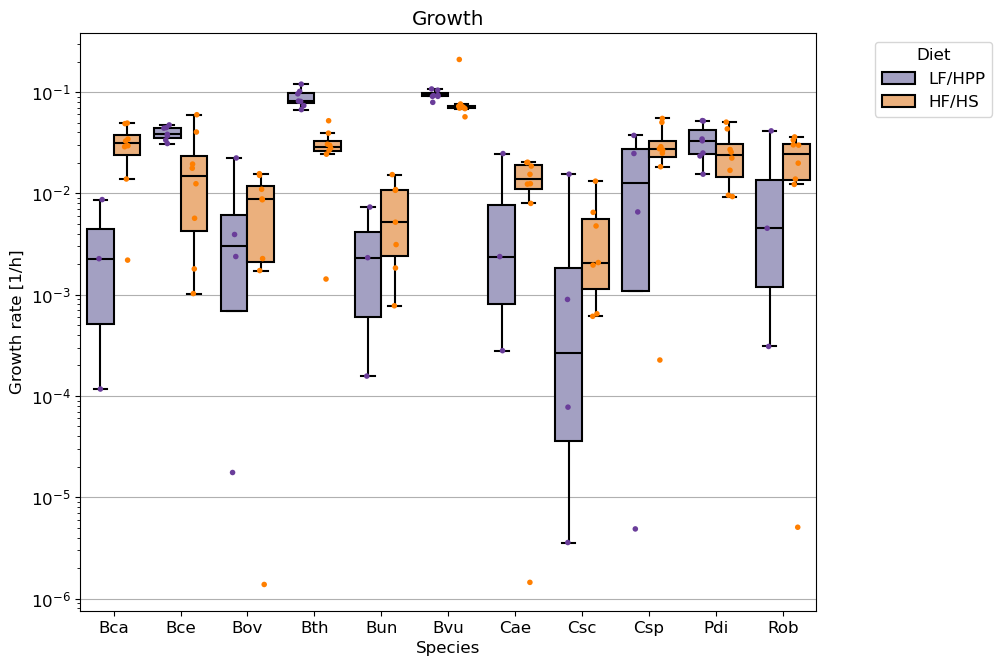

ANOVA
                  sum_sq     df          F        PR(>F)
diet         3396.787429    1.0  35.229433  2.116567e-08
taxon        3418.115590   10.0   3.545064  3.261790e-04
diet:taxon   2394.311881   10.0   2.483236  8.966462e-03
Residual    13787.920014  143.0        NaN           NaN
Tukey HSD
0                     group1                     group2 meandiff p-adj  lower  \
70  HF/HS:B_thetaiotaomicron  LF/HPP:B_thetaiotaomicron   0.0596   0.0  0.029   

0    upper reject  
70  0.0902   True  


In [5]:
growth_plot = growth[growth['growth_rate'] >= 1e-6].copy()
growth_plot['taxon'] = growth_plot['taxon'].map(abbr_names_dir)
plt.figure(figsize=(9.5, 7.5))
sns.stripplot(
    data=growth_plot, 
    x='taxon', 
    y='growth_rate', 
    hue='diet', 
    order= abbr_names_dir.values(),
    log_scale=True,
    size=4,
    # palette=[cm.tab20c(5), cm.tab20c(13)],
    palette=[cm.Paired(9), cm.Paired(7)],
    dodge=True,
    alpha=1,
    legend=False
    )
sns.boxplot(
    data=growth_plot, 
    x='taxon', 
    y='growth_rate', 
    hue='diet', 
    order= abbr_names_dir.values(),
    log_scale=True,
    saturation=0.75,
    # palette=[cm.Paired(7), cm.Paired(9)],
    palette=[cm.tab20c(13), cm.tab20c(6)],
    showfliers=False,
    # width=0.8,
    linewidth=1.5,
    linecolor='black'
    )
plt.legend(loc='upper right', title='Diet', bbox_to_anchor=(1.25, 1))
plt.xlabel('Species')
plt.ylabel('Growth rate [1/h]')
plt.title('Growth')
plt.grid(axis='y')
plt.savefig('results/growth_rates.svg', dpi=300, bbox_inches='tight')
plt.show()

model = ols('np.log(growth_rate) ~ diet + taxon + diet:taxon', data=growth).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print('ANOVA')
print(anova_table)

tukey_results = pairwise_tukeyhsd(growth['growth_rate'].values, growth['diet'].astype(str) + ":" + growth['taxon'].astype(str).values)
tukey_df = pd.DataFrame(tukey_results.summary().data)
tukey_df.columns = tukey_df.iloc[0]
tukey_df = tukey_df.drop(0)
tukey_df = tukey_df.reset_index(drop=True)
tukey_df['g1_diet'] = tukey_df['group1'].str.split(':').str[0].values
tukey_df['g2_diet'] = tukey_df['group2'].str.split(':').str[0].values
tukey_df['g1_taxon'] = tukey_df['group1'].str.split(':').str[1].values
tukey_df['g2_taxon'] = tukey_df['group2'].str.split(':').str[1].values
tukey_df_sig = tukey_df[(tukey_df['reject']==True) & (tukey_df['g1_taxon'] == tukey_df['g2_taxon'])]
tukey_df_sig = tukey_df_sig.loc[:, ['group1', 'group2', 'meandiff', 'p-adj', 'lower', 'upper', 'reject']]
print('Tukey HSD')
print(tukey_df_sig)

## Exchange fluxes

In [6]:
annot = minimal_imports_lf0.annotations
annot.index = annot.reaction
annot

,metabolite,name,molecular_weight,C_number,N_number,hmdb,inchi,kegg.compound,pubchem.compound,reaction
reaction,,,,,,,,,,
EX_12ppd_S(e),12ppd_S[e],"(S)-propane-1,2-diol",76.09442,3,0,HMDB06213,"InChI=1S/C3H8O2/c1-3(5)2-4/h3-5H,2H2,1H3/t3-/m...",C02917,NaN,EX_12ppd_S(e)
EX_2obut(e),2obut[e],2-Oxobutanoate,101.08070,4,0,HMDB00005,"InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7...",C00109,58.0,EX_2obut(e)
EX_4abut(e),4abut[e],4-Aminobutanoate,103.11976,4,1,HMDB00112,"InChI=1S/C4H9NO2/c5-3-1-2-4(6)7/h1-3,5H2,(H,6,7)",C00334,119.0,EX_4abut(e)
EX_4hbz(e),4hbz[e],4-hydroxybenzoate,137.11280,7,0,HMDB00500,"InChI=1S/C7H6O3/c8-6-3-1-5(2-4-6)7(9)10/h1-4,8...",C00156,NaN,EX_4hbz(e)
EX_MGlcn10(e),MGlcn10[e],mucin-type O-glycan No 10,NaN,44,4,NaN,NaN,NaN,NaN,EX_MGlcn10(e)
...,...,...,...,...,...,...,...,...,...,...
EX_mqn7_m,mqn7_m,Menaquinone 7,648.99916,46,0,NaN,NaN,C00828,4086.0,EX_mqn7_m
EX_n2_m,n2_m,Nitrogen,28.01340,0,2,NaN,NaN,NaN,NaN,EX_n2_m
EX_sbt_D_m,sbt_D_m,D-glucitol,182.17176,6,0,HMDB00247,InChI=1S/C6H14O6/c7-1-3(9)5(11)6(12)4(10)2-8/h...,C00794,5780.0,EX_sbt_D_m


### Imports

In [7]:
imports_lf0 = minimal_imports_lf0.exchanges
imports_lf0 = imports_lf0[imports_lf0['direction'] == 'import'].copy()
imports_lf0['diet'] = 'LF/HPP'
imports_hf0 = minimal_imports_hf0.exchanges
imports_hf0 = imports_hf0[imports_hf0['direction'] == 'import'].copy()
imports_hf0['diet'] = 'HF/HS'
imports = pd.concat([imports_lf0, imports_hf0], axis=0, ignore_index=True)
imports['flux'] = imports['flux'].abs() # note that the sign indicates the direction
imports

,taxon,sample_id,tolerance,reaction,flux,abundance,metabolite,direction,diet
0,medium,mouse_01,0.000001,EX_fol_m,0.000055,NaN,fol_m,import,LF/HPP
1,medium,mouse_01,0.000001,EX_q8_m,0.000007,NaN,q8_m,import,LF/HPP
2,medium,mouse_01,0.000001,EX_cobalt2_m,0.000200,NaN,cobalt2_m,import,LF/HPP
3,medium,mouse_01,0.000001,EX_zn2_m,0.000200,NaN,zn2_m,import,LF/HPP
4,medium,mouse_01,0.000001,EX_k_m,0.000200,NaN,k_m,import,LF/HPP
...,...,...,...,...,...,...,...,...,...
5948,C_aerofaciens,mouse_15,0.000001,EX_ser_L(e),100.000000,0.004272,ser_L[e],import,HF/HS
5949,C_aerofaciens,mouse_15,0.000001,EX_hxan(e),0.409947,0.004272,hxan[e],import,HF/HS
5950,C_aerofaciens,mouse_15,0.000001,EX_fru(e),100.000000,0.004272,fru[e],import,HF/HS
5951,C_aerofaciens,mouse_15,0.000001,EX_h(e),100.000000,0.004272,h[e],import,HF/HS


### Exports

In [8]:
exports_lf0 = minimal_imports_lf0.exchanges
exports_lf0 = exports_lf0[exports_lf0['direction'] == 'export'].copy()
exports_lf0['diet'] = 'LF/HPP'
exports_hf0 = minimal_imports_hf0.exchanges
exports_hf0 = exports_hf0[exports_hf0['direction'] == 'export'].copy()
exports_hf0['diet'] = 'HF/HS'
exports = pd.concat([exports_lf0, exports_hf0], axis=0, ignore_index=True)
exports

,taxon,sample_id,tolerance,reaction,flux,abundance,metabolite,direction,diet
0,medium,mouse_01,0.000001,EX_h2o_m,0.345596,NaN,h2o_m,export,LF/HPP
1,medium,mouse_01,0.000001,EX_cspg_ab_rest_m,0.000026,NaN,cspg_ab_rest_m,export,LF/HPP
2,medium,mouse_01,0.000001,EX_ttdca_m,0.000521,NaN,ttdca_m,export,LF/HPP
3,medium,mouse_01,0.000001,EX_hspg_degr_13_m,0.000114,NaN,hspg_degr_13_m,export,LF/HPP
4,medium,mouse_01,0.000001,EX_idour_m,0.000255,NaN,idour_m,export,LF/HPP
...,...,...,...,...,...,...,...,...,...
2469,C_aerofaciens,mouse_15,0.000001,EX_tyr_L(e),0.000002,0.004272,tyr_L[e],export,HF/HS
2470,C_aerofaciens,mouse_15,0.000001,EX_pro_L(e),100.000000,0.004272,pro_L[e],export,HF/HS
2471,C_aerofaciens,mouse_15,0.000001,EX_co2(e),199.590049,0.004272,co2[e],export,HF/HS
2472,C_aerofaciens,mouse_15,0.000001,EX_12dhchol(e),100.000000,0.004272,12dhchol[e],export,HF/HS


## Consumption and production rates

### Consumption

In [9]:
consumption_lf0 = consumption_rates(minimal_imports_lf0)
consumption_lf0['diet'] = 'LF/HPP'
consumption_hf0 = consumption_rates(minimal_imports_hf0)
consumption_hf0['diet'] = 'HF/HS'
consumption = pd.concat([consumption_lf0, consumption_hf0], axis=0, ignore_index=True)
consumption

,sample_id,metabolite,flux,name,molecular_weight,C_number,N_number,hmdb,inchi,kegg.compound,pubchem.compound,reaction,diet
0,mouse_01,12dhchol[e],0.630261,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
1,mouse_02,12dhchol[e],0.613308,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
2,mouse_03,12dhchol[e],1.249506,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
3,mouse_04,12dhchol[e],0.116578,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
4,mouse_05,12dhchol[e],0.754904,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1515,mouse_15,core2_rl[e],0.046656,released Core 2,586.54092,22,2,NaN,NaN,NaN,NaN,EX_core2_rl(e),HF/HS
1516,mouse_13,gncore2_rl[e],0.046557,"released GlcNAc-alpha-1,4-Core 2",789.73344,30,3,NaN,NaN,NaN,NaN,EX_gncore2_rl(e),HF/HS
1517,mouse_14,gncore2_rl[e],0.073168,"released GlcNAc-alpha-1,4-Core 2",789.73344,30,3,NaN,NaN,NaN,NaN,EX_gncore2_rl(e),HF/HS
1518,mouse_15,gncore2_rl[e],0.046656,"released GlcNAc-alpha-1,4-Core 2",789.73344,30,3,NaN,NaN,NaN,NaN,EX_gncore2_rl(e),HF/HS


In [10]:
consumption_pivot = pd.pivot_table(consumption, index=['diet', 'sample_id'], columns='name', values='flux')
consumption_pivot = consumption_pivot.T.fillna(0)
consumption_pivot = consumption_pivot.apply(lambda x: np.log10(x + 1e-6), axis=0)
consumption_pivot = consumption_pivot[['LF/HPP', 'HF/HS']]
consumption_pivot

diet                                LF/HPP                                \
sample_id                         mouse_01  mouse_02  mouse_03  mouse_04   
name                                                                       
(R)-Pantothenate                 -6.000000 -5.950207 -5.536553 -5.397120   
(R)-lactate                       1.802612  1.785493  1.778380  1.560587   
(S)-lactate                       1.523577  1.608356  1.589664  1.765607   
12-Dehydrocholate                -0.200479 -0.212321  0.096739 -0.933381   
2-Oxobutanoate                   -1.664787 -1.505516 -1.705422 -1.789561   
...                                    ...       ...       ...       ...   
released Core 2                  -1.331837 -1.331492 -6.000000 -6.000000   
released GlcNAc-alpha-1,4-Core 2 -1.331837 -1.331492 -6.000000 -1.377915   
sulfate                          -2.906854 -2.850509 -2.889958 -2.839555   
tetradecanoate (n-C14:0)         -3.262510 -2.596622 -3.056428 -2.607568   
uracil                           -6.000000 -2.958587 -4.311704 -5.399796   

diet                                                               HF/HS  \
sample_id                         mouse_05  mouse_06  mouse_07  mouse_08   
name                                                                       
(R)-Pantothenate                 -6.000000 -6.000000 -6.000000 -5.272177   
(R)-lactate                       1.805993  1.571395  1.744840  1.554009   
(S)-lactate                       1.614863  1.786790  1.715893  1.684297   
12-Dehydrocholate                -0.122108 -0.326892  0.031640 -0.376824   
2-Oxobutanoate                   -1.707079 -1.618735 -1.768277 -1.740852   
...                                    ...       ...       ...       ...   
released Core 2                  -1.331449 -1.331530 -1.331555 -6.000000   
released GlcNAc-alpha-1,4-Core 2 -1.331449 -1.331530 -1.331555 -6.000000   
sulfate                          -2.882726 -2.898676 -2.963053 -2.859568   
tetradecanoate (n-C14:0)         -2.590086 -2.619092 -2.619093 -2.594863   
uracil                           -3.675129 -3.706545 -3.269596 -4.294894   

diet                                                                      \
sample_id                         mouse_09  mouse_10  mouse_11  mouse_12   
name                                                                       
(R)-Pantothenate                 -5.180208 -5.613516 -5.171699 -5.252582   
(R)-lactate                       1.520479  1.778419  1.788229  1.616077   
(S)-lactate                       1.746497  1.463992  1.556749  1.820424   
12-Dehydrocholate                -0.528487 -0.717414 -1.904865 -1.482275   
2-Oxobutanoate                   -2.079210  0.534864 -2.113238 -1.675382   
...                                    ...       ...       ...       ...   
released Core 2                  -6.000000 -6.000000 -6.000000 -6.000000   
released GlcNAc-alpha-1,4-Core 2 -6.000000 -6.000000 -6.000000 -6.000000   
sulfate                          -2.841005 -3.850457 -2.848173 -2.840834   
tetradecanoate (n-C14:0)         -2.545103 -3.236067 -2.608910 -2.993084   
uracil                           -4.349794 -2.279462 -5.547825 -5.227613   

diet                                                            
sample_id                         mouse_13  mouse_14  mouse_15  
name                                                            
(R)-Pantothenate                 -5.290824 -5.689219 -5.999810  
(R)-lactate                       1.679400  1.667132  1.714690  
(S)-lactate                       1.528570  1.221894  1.485711  
12-Dehydrocholate                -0.474655 -0.710711 -0.369353  
2-Oxobutanoate                   -1.727244 -1.294732 -1.927194  
...                                    ...       ...       ...  
released Core 2                  -1.332007 -1.135670 -1.331088  
released GlcNAc-alpha-1,4-Core 2 -1.332007 -1.135670 -1.331088  
sulfate                          -2.869293 -2.865346 -2.855224  
tetradecanoate (n-C14:0) 

In [11]:
# variance
consumption_pivot_var = consumption_pivot. \
    copy(). \
        reindex(consumption_pivot.var(axis=1).sort_values(ascending=False).index). \
            head(30)
consumption_pivot_var

diet                                                  LF/HPP            \
sample_id                                           mouse_01  mouse_02   
name                                                                     
D-ribose                                           -0.148067 -6.000000   
3alpha,12alpha-Dihydroxy-7-oxo-5beta-cholanate      0.073782  0.126624   
released Core 2                                    -1.331837 -1.331492   
Beta-1,6-N-acetylglucosamine-N-acetylgalactosamine -1.331837 -1.331492   
released GlcNAc-alpha-1,4-Core 2                   -1.331837 -1.331492   
Tn antigen                                         -6.000000 -6.000000   
GlcNAc-alpha-1,4-Core 2                            -6.000000 -6.000000   
T antigen (core 1)                                 -6.000000 -6.000000   
GlcNAc-alpha-1,4-Core 1                            -6.000000 -6.000000   
Indole                                              0.369093  0.308476   
Core 2                                             -6.000000 -6.000000   
Inosine                                            -2.280773  0.650201   
Hexadecanoate (n-C16:0)                            -6.000000 -2.730380   
Glycerol                                           -4.161019 -0.212136   
L-tryptophan                                        0.369093  0.308282   
Adenosine                                          -2.772216  0.650528   
N-acetylneuraminate                                 0.556693  0.874127   
Xanthine                                           -2.118978 -2.756899   
Hydrogen sulfide                                   -1.846711 -2.368555   
L-cysteine                                         -1.855755 -2.117234   
2-deoxyadenosine                                   -6.000000 -2.958999   
meso-2,6-Diaminoheptanedioate                      -6.000000 -6.000000   
Beta-1,3-Galactose-N-acetylgalactosamine           -6.000000 -6.000000   
L-tyrosine                                         -6.000000 -5.505419   
uracil                                             -6.000000 -2.958587   
Uridine                                             1.026374  1.282298   
Cytidine                                            1.026454  1.282321   
Product GAM2STASE_HS3, GlcN-IdoA-GlcNAc-GlcA-Ga... -3.938392 -6.000000   
Product IDOURASE_HS2, GlcN2,6diS-IdoA-GlcNAc3S-... -3.938392 -6.000000   
Product AS6TASE_HS1, GlcN2S-GlcA-GlcN2,3diS        -6.000000 -6.000000   

diet                                                                    \
sample_id                                           mouse_03  mouse_04   
name                                                                     
D-ribose                                           -6.000000 -6.000000   
3alpha,12alpha-Dihydroxy-7-oxo-5beta-cholanate      0.481731 -0.385188   
released Core 2                                    -6.000000 -6.000000   
Beta-1,6-N-acetylglucosamine-N-acetylgalactosamine -6.000000 -6.000000   
released GlcNAc-alpha-1,4-Core 2                   -6.000000 -1.377915   
Tn antigen                                         -1.331693 -2.330073   
GlcNAc-alpha-1,4-Core 2                            -1.331693 -2.330073   
T antigen (core 1)                                 -1.331693 -2.330073   
GlcNAc-alpha-1,4-Core 1                            -6.000000 -6.000000   
Indole                                              0.646713  1.224691   
Core 2                                             -1.331693 -2.330073   
Inosine                                            -3.673449 -2.727104   
Hexadecanoate (n-C16:0)                            -6.000000 -2.725145   
Glycerol                                            0.475033 -0.933175   
L-tryptophan                                        0.646853  1.224676   
Adenosine                                          -2.141679 -2.032635   
N-acetylneuraminate                                 0.793494  0.728099   
Xanthine                                           -2.178262 -6.000000   
Hyd

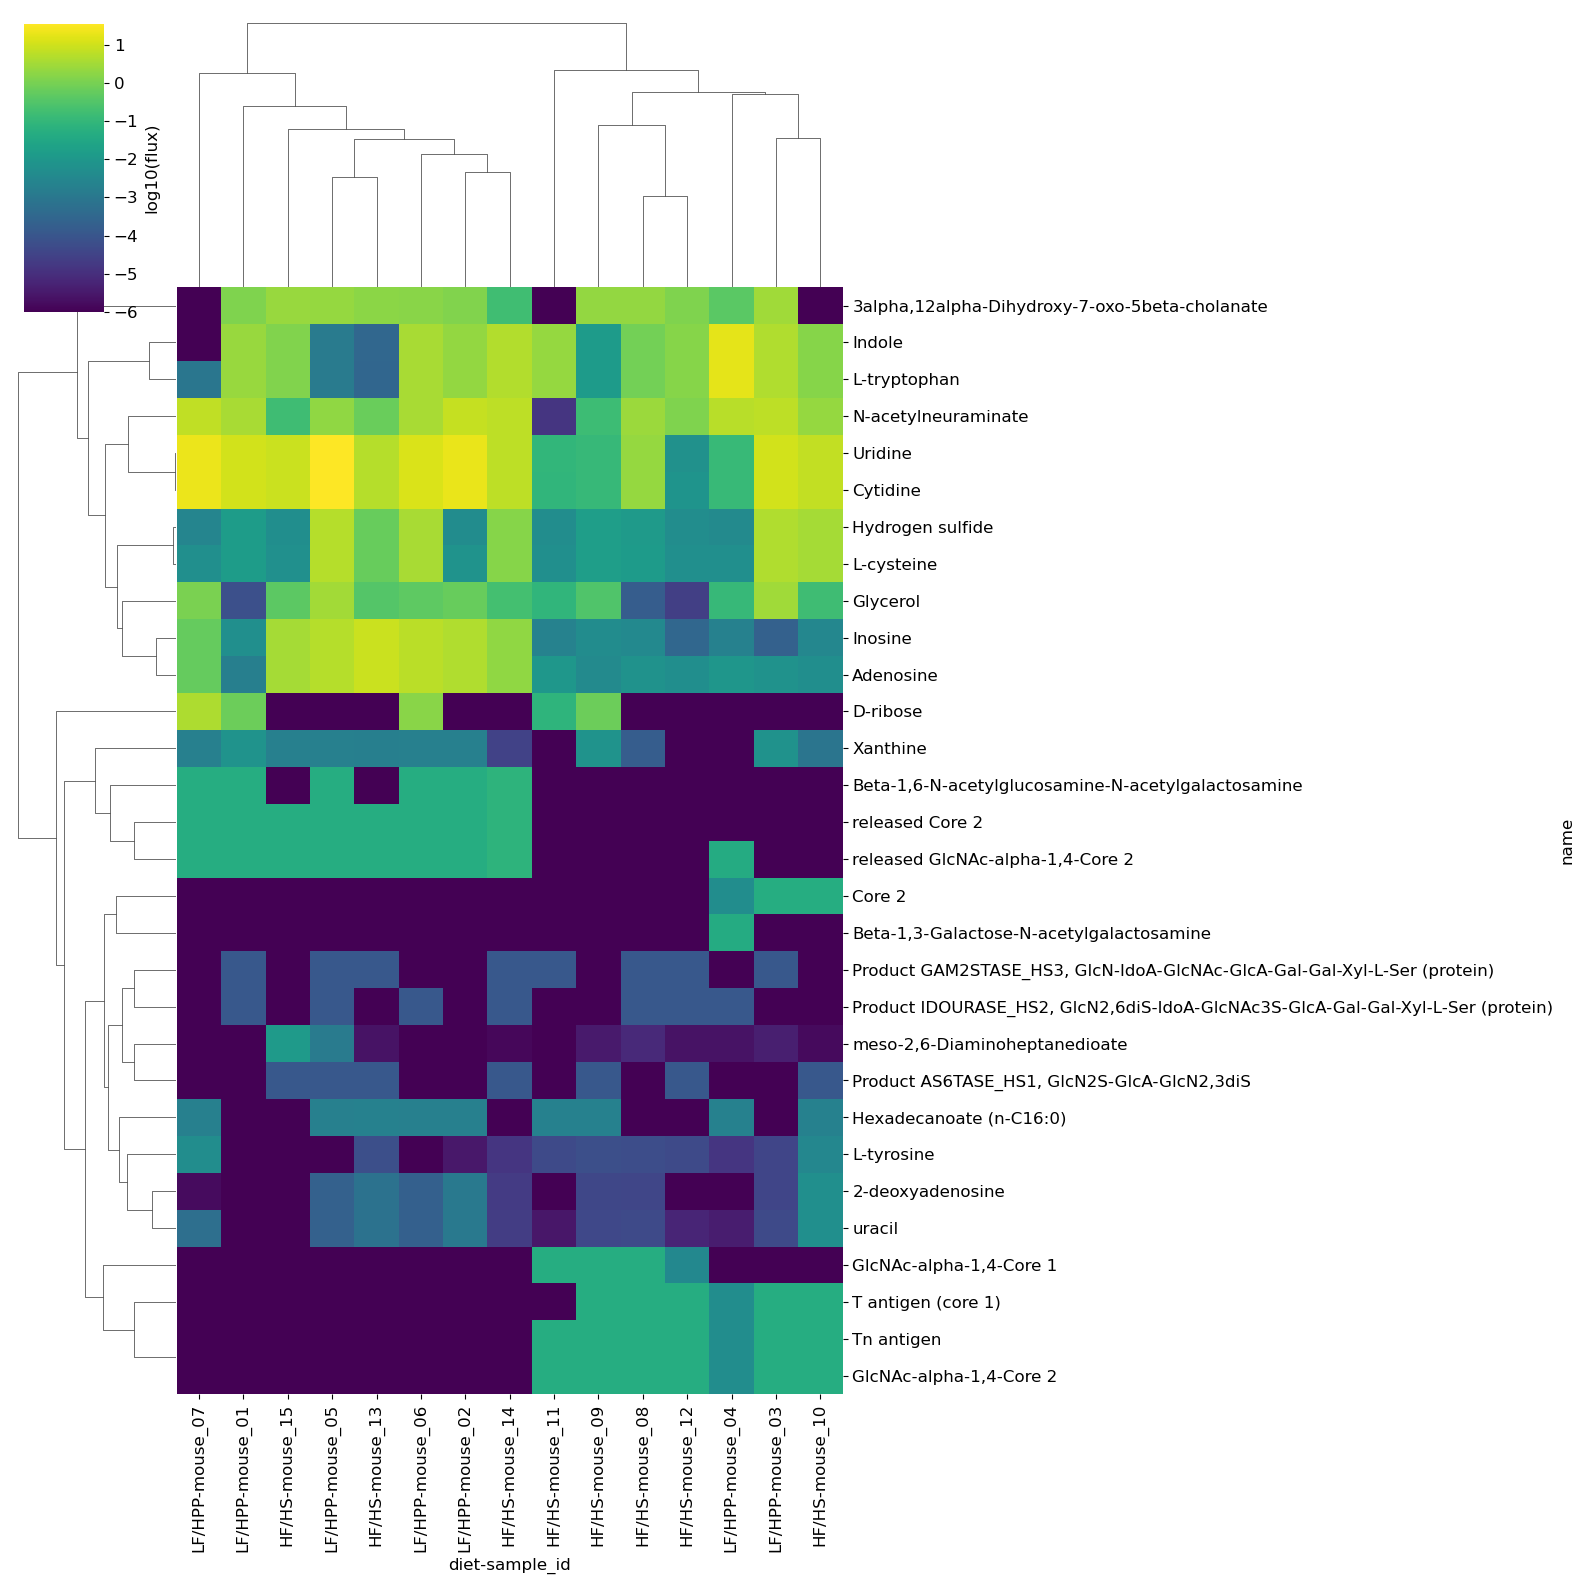

In [12]:
sns.clustermap(
    consumption_pivot_var,  # take 50 highest fluxes
    cmap='viridis',
    cbar_kws={'label': 'log10(flux)'},
    # col_cluster=False,
    yticklabels=True,    # show all metabolite names
    figsize=(16, 16)      # size of the heatmap
)
plt.savefig('results/consumption_var.svg', dpi=300, bbox_inches='tight')
plt.show()

### Production

In [13]:
production_lf0 = production_rates(minimal_imports_lf0)
production_lf0['diet'] = 'LF/HPP'
production_hf0 = production_rates(minimal_imports_hf0)
production_hf0['diet'] = 'HF/HS'
production = pd.concat([production_lf0, production_hf0], axis=0, ignore_index=True)
production

,sample_id,metabolite,flux,name,molecular_weight,C_number,N_number,hmdb,inchi,kegg.compound,pubchem.compound,reaction,diet
0,mouse_01,12dhchol[e],0.630261,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
1,mouse_02,12dhchol[e],0.613308,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
2,mouse_03,12dhchol[e],1.249506,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
3,mouse_04,12dhchol[e],0.116578,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
4,mouse_05,12dhchol[e],0.754904,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1244,mouse_12,hspg_degr_2[e],0.000114,"Product 2 HEPARL1_e, IdoA2S-GlcN2,6diS-IdoA2S-...",NaN,49,2,NaN,NaN,NaN,NaN,EX_hspg_degr_2(e),HF/HS
1245,mouse_13,core2_rl[e],0.046557,released Core 2,586.54092,22,2,NaN,NaN,NaN,NaN,EX_core2_rl(e),HF/HS
1246,mouse_14,core2_rl[e],0.073168,released Core 2,586.54092,22,2,NaN,NaN,NaN,NaN,EX_core2_rl(e),HF/HS
1247,mouse_15,core2_rl[e],0.046656,released Core 2,586.54092,22,2,NaN,NaN,NaN,NaN,EX_core2_rl(e),HF/HS


In [14]:
production_pivot = pd.pivot_table(production, index=['diet', 'sample_id'], columns='name', values='flux')
production_pivot = production_pivot.T.fillna(0)
production_pivot = production_pivot.apply(lambda x: np.log10(x + 1e-6), axis=0)
production_pivot = production_pivot[['LF/HPP', 'HF/HS']]
production_pivot

diet                        LF/HPP                                          \
sample_id                 mouse_01  mouse_02  mouse_03  mouse_04  mouse_05   
name                                                                         
(R)-lactate               1.802612  1.785493  1.778380  1.560587  1.805993   
(S)-lactate               1.523577  1.608356  1.589664  1.765607  1.614863   
12-Dehydrocholate        -0.200479 -0.212321  0.096739 -0.933381 -0.122108   
2-Oxobutanoate           -1.664787 -1.505516 -1.705422 -1.789561 -1.707079   
2-deoxyadenosine         -6.000000 -2.958999 -4.462360 -6.000000 -3.675129   
...                            ...       ...       ...       ...       ...   
proton                    1.673409  1.768877  1.679639  1.178554  1.678050   
released Core 2          -1.331837 -1.331492 -6.000000 -6.000000 -1.331449   
sulfate                  -2.906854 -2.850491 -2.889958 -2.839555 -2.882726   
tetradecanoate (n-C14:0) -2.971697 -2.596622 -3.056428 -2.565127 -2.590086   
uracil                   -6.000000 -2.958587 -4.311704 -5.399796 -3.675129   

diet                                             HF/HS                      \
sample_id                 mouse_06  mouse_07  mouse_08  mouse_09  mouse_10   
name                                                                         
(R)-lactate               1.571395  1.744840  1.554009  1.520479  1.778419   
(S)-lactate               1.786790  1.715893  1.684297  1.746497  1.463992   
12-Dehydrocholate        -0.326892  0.031640 -0.376824 -0.528487 -0.717414   
2-Oxobutanoate           -1.618735 -1.768277 -1.740852 -2.079210  0.534864   
2-deoxyadenosine         -3.706545 -5.773636 -4.430692 -4.400372 -2.279667   
...                            ...       ...       ...       ...       ...   
proton                    1.716517  1.822095  1.449014  1.698670  1.626688   
released Core 2          -1.331530 -1.331555 -6.000000 -6.000000 -6.000000   
sulfate                  -2.898676 -2.963046 -2.859568 -2.841005 -3.850457   
tetradecanoate (n-C14:0) -2.619092 -2.619081 -2.594863 -2.545103 -3.236067   
uracil                   -3.706545 -3.269596 -4.294894 -4.349794 -2.279462   

diet                                                                        
sample_id                 mouse_11  mouse_12  mouse_13  mouse_14  mouse_15  
name                                                                        
(R)-lactate               1.788229  1.616077  1.679400  1.667132  1.714690  
(S)-lactate               1.556749  1.820424  1.528570  1.221894  1.485711  
12-Dehydrocholate        -1.904865 -1.482275 -0.474655 -0.710711 -0.369353  
2-Oxobutanoate           -2.113238 -1.675382 -1.727244 -1.294732 -1.927194  
2-deoxyadenosine         -6.000000 -6.000000 -3.155610 -4.690827 -6.000000  
...                            ...       ...       ...       ...       ...  
proton                    1.370066  1.776916  1.556750  1.457591  1.528645  
released Core 2          -6.000000 -6.000000 -1.332007 -1.135670 -1.331088  
sulfate                  -2.848173 -2.840834 -2.869293 -2.865346 -2.855224  
tetradecanoate (n-C14:0) -2.608910 -2.993084 -2.582835 -2.179611 -2.537871  
uracil                   -5.547825 -5.227613 -3.151480 -4.657904 -6.000000  

[104 rows x 15 columns]

In [15]:
# variance
production_pivot_var = production_pivot. \
    copy(). \
        reindex(production_pivot.var(axis=1).sort_values(ascending=False).index). \
            head(30)
production_pivot_var

diet                                                  LF/HPP            \
sample_id                                           mouse_01  mouse_02   
name                                                                     
L-cysteine                                         -2.064172 -6.000000   
D-ribose                                           -0.148067 -6.000000   
3alpha,12alpha-Dihydroxy-7-oxo-5beta-cholanate      0.073782  0.126624   
released Core 2                                    -1.331837 -1.331492   
Beta-1,6-N-acetylglucosamine-N-acetylgalactosamine -1.331837 -1.331492   
protein-linked serine or threonine residue (O-g... -6.000000 -6.000000   
Tn antigen                                         -6.000000 -6.000000   
T antigen (core 1)                                 -6.000000 -6.000000   
L-argininium(1+)                                   -6.000000 -0.243490   
GlcNAc-alpha-1,4-Core 1                            -6.000000 -6.000000   
Indole                                              0.369093  0.308476   
propionate                                         -1.625962 -1.635357   
Core 2                                             -6.000000 -6.000000   
Inosine                                            -2.280773  0.650201   
Hexadecanoate (n-C16:0)                            -6.000000 -2.730380   
Glycerol                                           -4.161019 -0.212136   
L-tryptophan                                        0.369093  0.308282   
Adenosine                                          -2.772216  0.650528   
Hypoxanthine                                       -2.118978 -6.000000   
N-acetylneuraminate                                 0.556693  0.874127   
Xanthine                                           -2.118978 -2.756899   
Hydrogen sulfide                                   -1.846711 -2.368555   
2-deoxyadenosine                                   -6.000000 -2.958999   
meso-2,6-Diaminoheptanedioate                      -6.000000 -6.000000   
Beta-1,3-Galactose-N-acetylgalactosamine           -6.000000 -6.000000   
L-tyrosine                                         -6.000000 -5.505419   
uracil                                             -6.000000 -2.958587   
Uridine                                             1.026374  1.282298   
Cytidine                                            1.026454  1.282321   
Product IDOURASE_HS2, GlcN2,6diS-IdoA-GlcNAc3S-... -3.938392 -6.000000   

diet                                                                    \
sample_id                                           mouse_03  mouse_04   
name                                                                     
L-cysteine                                          0.646387 -6.000000   
D-ribose                                           -6.000000 -6.000000   
3alpha,12alpha-Dihydroxy-7-oxo-5beta-cholanate      0.481731 -0.385188   
released Core 2                                    -6.000000 -6.000000   
Beta-1,6-N-acetylglucosamine-N-acetylgalactosamine -6.000000 -6.000000   
protein-linked serine or threonine residue (O-g... -1.331693 -2.330073   
Tn antigen                                         -1.331693 -2.330073   
T antigen (core 1)                                 -1.331693 -2.330073   
L-argininium(1+)                                    0.080483 -1.141274   
GlcNAc-alpha-1,4-Core 1                            -6.000000 -6.000000   
Indole                                              0.646713  1.224691   
propionate                                         -1.641143 -6.000000   
Core 2                                             -1.331693 -2.330073   
Inosine                                            -3.673449 -2.727104   
Hexadecanoate (n-C16:0)                            -6.000000 -2.725145   
Glycerol                                            0.475033 -0.933175   
L-tryptophan                                        0.646853  1.224676   
Adenosine                                          -2.141679 -2.032635   
Hyp

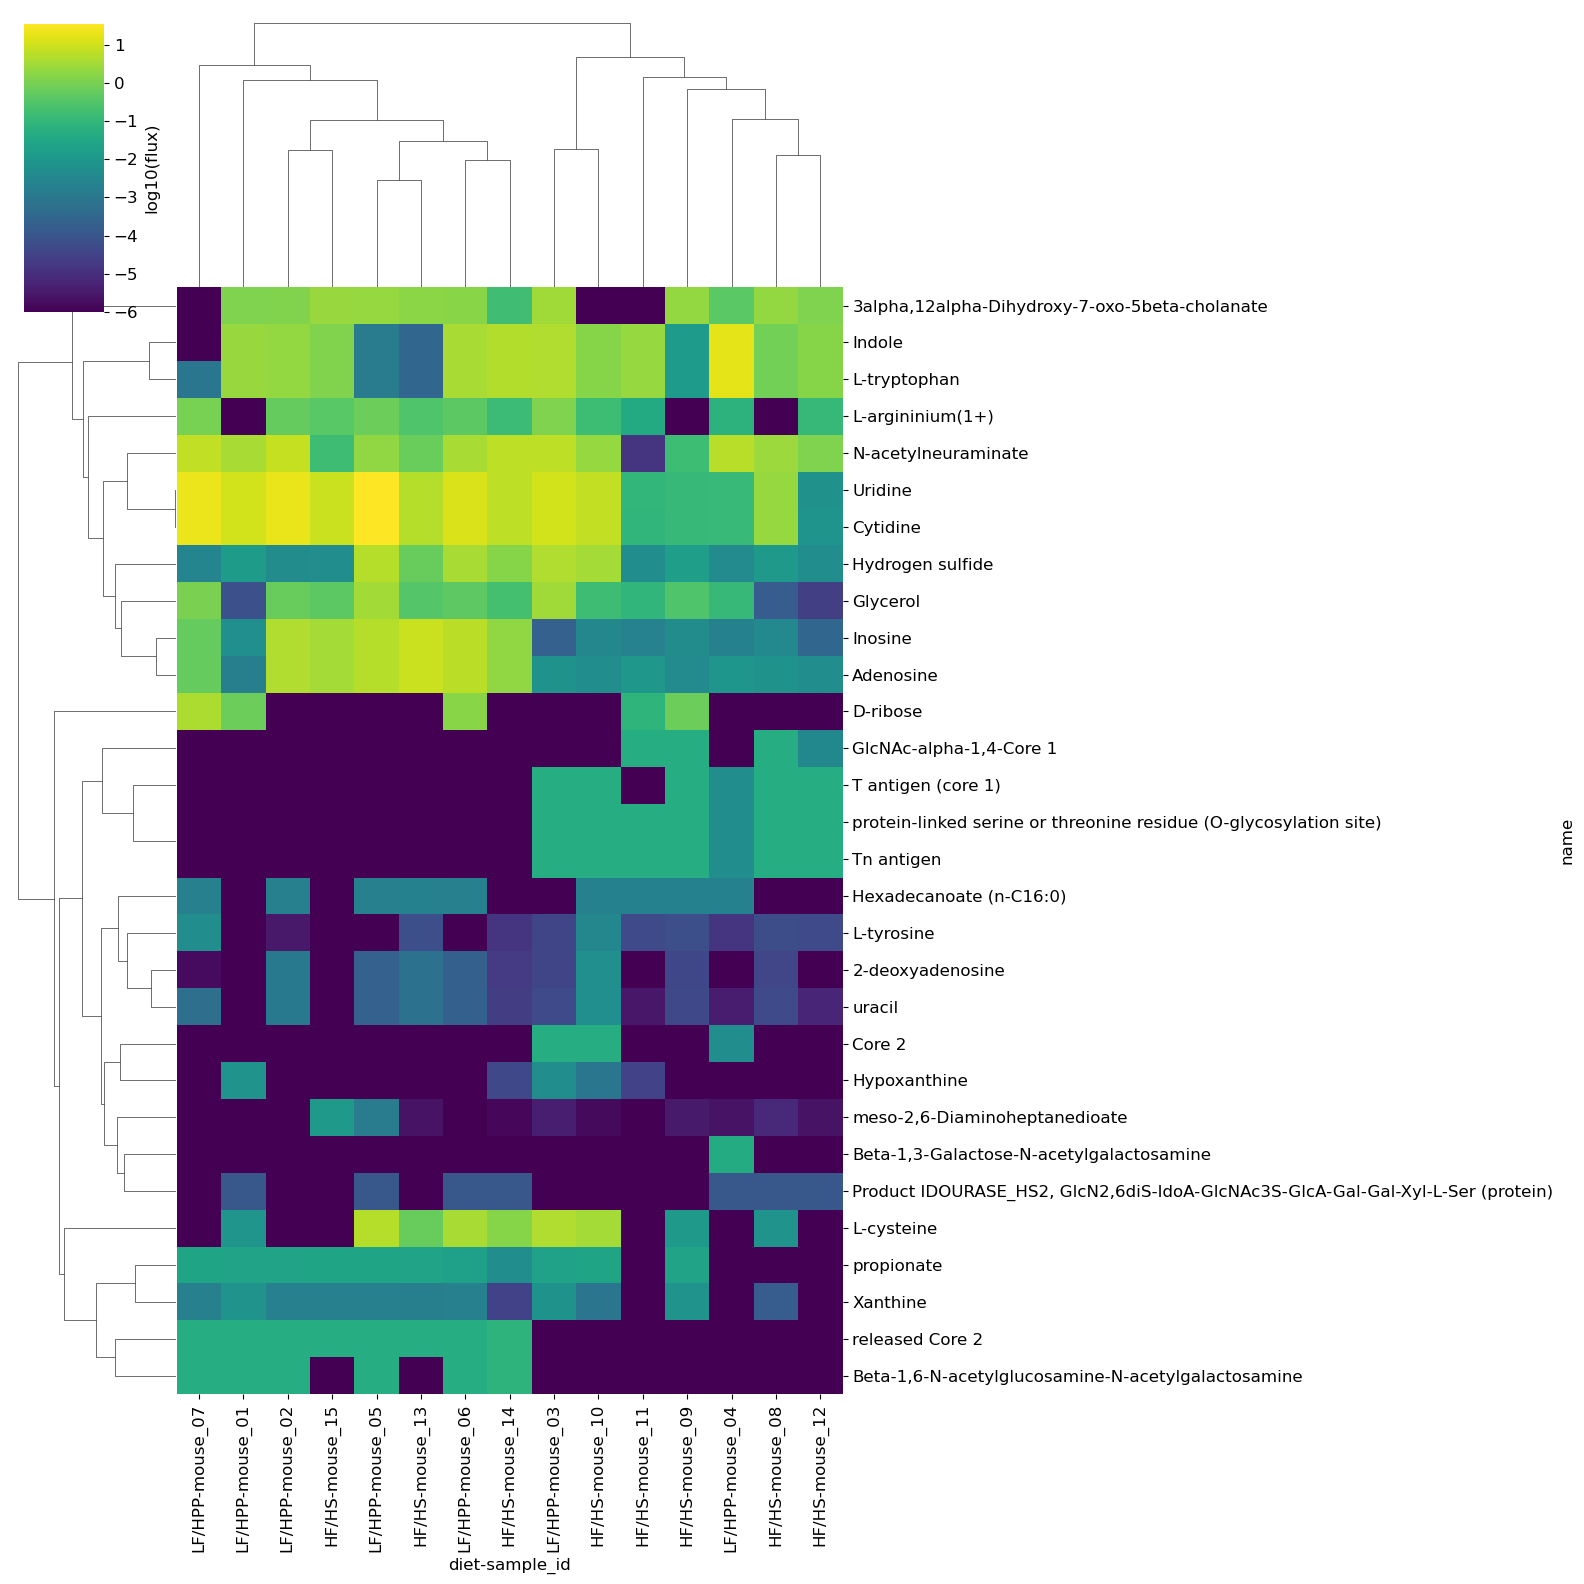

In [16]:
sns.clustermap(
    production_pivot_var,  # take 50 highest fluxes
    cmap='viridis',
    cbar_kws={'label': 'log10(flux)'},
    yticklabels=True,    # show all metabolite names
    figsize=(16, 16)      # size of the heatmap
)
plt.savefig('results/production_var.svg', dpi=300, bbox_inches='tight')
plt.show()

## Metabolic Niche

In [17]:
plt.rc('font', size=16)

In [18]:
# Define useful lookup variables
cols = ['#016bff',
        '#b91f1c',
        '#308937',
        '#ff8137',
        '#6f4fc7',
        '#d4b300',
        '#893a2b',
        '#ff6c79',
        '#16c4ff',
        '#766f41',
        '#00c800',
        # '#af3261'
        ]

pretty_names_dir = {'B_caccae': '$B. caccae$',
                'B_cellulosilyticus_WH2': '$B. cellulosilyticus$',
                'B_ovatus': '$B. ovatus$',
                'B_thetaiotaomicron': '$B. thetaiotaomicron$',
                'B_uniformis': '$B. uniformis$',
                'B_vulgatus': '$B. vulgatus$',
                'C_aerofaciens': '$C. aerofaciens$',
                'C_scindens': '$C. scindens$',
                'C_spiroforme': '$C. spiroforme$',
                # 'D_longicatena': '$D. longicatena$',
                'P_distasonis': '$P. distasonis$',
                'R_obeum': '$R. obeum$'
                }

order = ['B_cellulosilyticus_WH2', 
        'B_caccae', 
        'B_vulgatus', 
        'B_thetaiotaomicron', 
        'B_ovatus', 
        'R_obeum', 
        'B_uniformis', 
        'P_distasonis', 
        'C_scindens', 
        'C_aerofaciens', 
        'C_spiroforme', 
        # 'D_longicatena'
        ]

lf0 = ['1', '2', '3', '4', '5', '6', '7']
hf0 = ['8', '9', '10', '11', '12', '13', '14', '15']

taxa_color = {order: cols[i] for i, order in enumerate(order)}
taxa_color

cols_ordered = [taxa_color[i] for i in pretty_names_dir.keys()] 
cols_ordered

['#b91f1c',
 '#016bff',
 '#6f4fc7',
 '#ff8137',
 '#893a2b',
 '#308937',
 '#766f41',
 '#16c4ff',
 '#00c800',
 '#ff6c79',
 '#d4b300']

### Imports

In [19]:
imports_ = imports[imports['taxon'] != 'medium'].copy()
imports_['taxon'] = imports_['taxon'].map(abbr_names_dir)
imports_.rename(columns={'taxon':'Species', 'diet':'Diet'}, inplace=True)
imports_['flux'] = imports_['flux'] * imports_['abundance']
imports_mat = imports_.pivot_table(index=['Diet', 'sample_id', 'Species'], values='flux', columns='reaction', fill_value=0.0)
imports_mat

reaction                  EX_12dhchol(e)  EX_26dap_M(e)  EX_2obut(e)  \
Diet   sample_id Species                                               
HF/HS  mouse_08  Bca            0.000000       0.000000     0.011195   
                 Bce            0.000000       0.000000     0.000000   
                 Bov            0.000000       0.000000     0.000043   
                 Bth            0.000000       0.000000     0.001726   
                 Bun            0.000000       0.000005     0.000000   
...                                  ...            ...          ...   
LF/HPP mouse_07  Cae            0.000000       0.000000     0.000000   
                 Csc            1.075572       0.000000     0.000000   
                 Csp            0.000000       0.000000     0.000000   
                 Pdi            0.000000       0.000000     0.000000   
                 Rob            0.000000       0.000000     0.000000   

reaction                  EX_7dhcdchol(e)  EX_7ocholate(e)  EX_C02528(e)  \
Diet   sample_id Species                                                   
HF/HS  mouse_08  Bca             0.000000         0.000000      0.000000   
                 Bce             0.000000         0.000000      0.000000   
                 Bov             0.000000         0.000000      0.000000   
                 Bth             0.000000         2.090003      1.670075   
                 Bun             0.000000         0.000000      0.000000   
...                                   ...              ...           ...   
LF/HPP mouse_07  Cae             0.000000         0.000000      0.000000   
                 Csc             2.261624         0.000000      0.000000   
                 Csp             0.000000         0.000000      0.000000   
                 Pdi             0.000000         0.000000      0.000000   
                 Rob             0.000000         0.000000      0.000000   

reaction                  EX_T_antigen(e)  EX_Tn_antigen(e)   EX_ac(e)  \
Diet   sample_id Species                                                 
HF/HS  mouse_08  Bca                  0.0          0.046567   0.000000   
                 Bce                  0.0          0.000000  15.875106   
                 Bov                  0.0          0.000000   0.000000   
                 Bth                  0.0          0.000000   0.000000   
                 Bun                  0.0          0.000000   3.013094   
...                                   ...               ...        ...   
LF/HPP mouse_07  Cae                  0.0          0.000000   0.000000   
                 Csc                  0.0          0.000000   0.000000   
                 Csp                  0.0          0.000000   0.000000   
                 Pdi                  0.0          0.000000   0.000000   
                 Rob                  0.0          0.000000   0.000000   

reaction                  EX_acald(e)  ...  EX_thr_L(e)  EX_thymd(e)  \
Diet   sample_id Species               ...                             
HF/HS  mouse_08  Bca         0.000000  ...     0.000000     0.000109   
                 Bce         0.000000  ...     0.001639     0.000078   
                 Bov         0.000000  ...     0.000038     0.000002   
                 Bth         0.000000  ...     0.001114     0.000085   
                 Bun         0.000000  ...     0.000039     0.000002   
...                               ...  ...          ...          ...   
LF/HPP mouse_07  Cae         0.000000  ...     0.000000     0.000000   
                 Csc         2.261624  ...     0.000000     0.000000   
                 Csp         0.000000  ...     0.000000     0.000000   
                 Pdi         0.000000  ...     0.000418     0.000000   
                 Rob         0.595739  ...     0.000000     0.000000   

reaction                  EX_trp_L(e)  EX_ttdca(e)  EX_tyr_L(e)  EX_ura(e)  \
Diet   sample_id Species                                                     
HF/HS  mouse_08  B

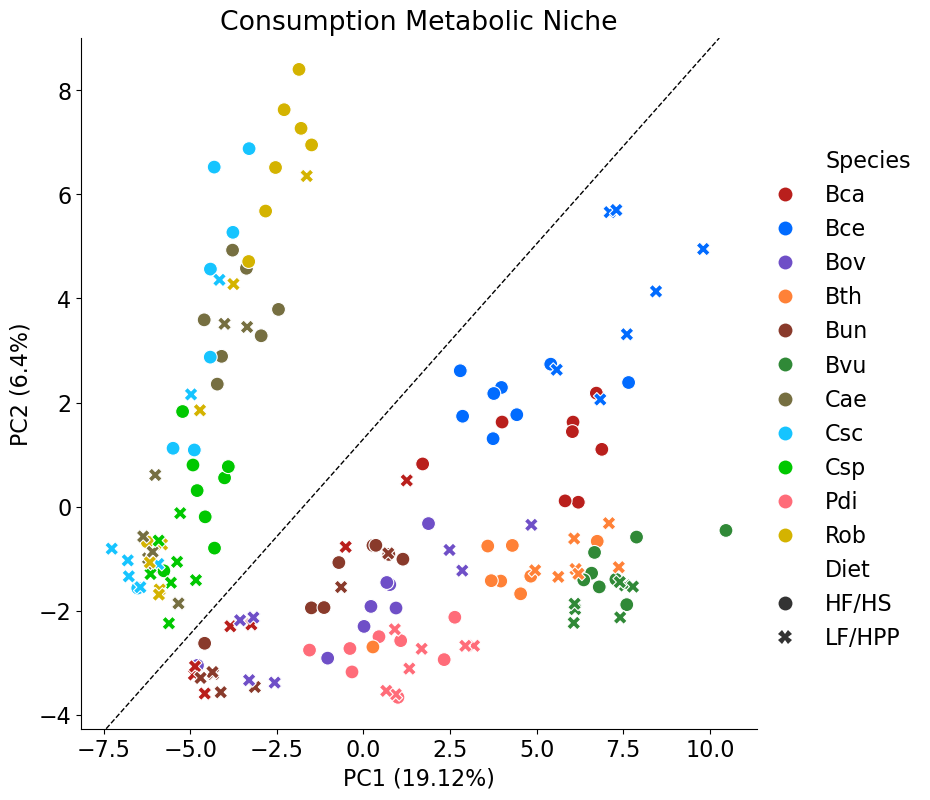

In [20]:
x = imports_mat.values
x = np.log10(x+1e-7)
x = StandardScaler().fit_transform(x)
y = imports_mat.index

pca = PCA(n_components=2)
principalComponents = pca.fit_transform(x)
principalDf = pd.DataFrame(data = principalComponents, columns = ['PC1', 'PC2'])
principalDf.index = y
expl_var = np.round(pca.explained_variance_ratio_* 100, decimals=2)

sns.relplot(
    data=principalDf, 
    x='PC1', 
    y='PC2', 
    hue='Species', 
    style='Diet', 
    palette=cols_ordered, 
    height=8, 
    aspect=1, 
    s=100
    )
plt.title('Consumption Metabolic Niche')
plt.xlabel(f'PC1 ({expl_var[0]}%)')
plt.ylabel(f'PC2 ({expl_var[1]}%)')
plt.axline((-0.4, 1), slope=0.75, color='black', linestyle='--', linewidth=1)
plt.savefig('results/consumption_met_niche_total.svg', dpi=300, bbox_inches='tight')
plt.show()

### Exports

In [21]:
exports_ = exports[exports['taxon'] != 'medium'].copy()
exports_['taxon'] = exports_['taxon'].map(abbr_names_dir)
exports_.rename(columns={'taxon':'Species', 'diet':'Diet'}, inplace=True)
exports_['flux'] = exports_['flux'] * exports_['abundance']
exports_mat = exports_.pivot_table(index=['Diet', 'sample_id', 'Species'], values='flux', columns='reaction', fill_value=0.0)
exports_mat

reaction                  EX_12dhchol(e)  EX_26dap_M(e)  EX_2obut(e)  \
Diet   sample_id Species                                               
HF/HS  mouse_08  Bca            0.000000            0.0      0.00000   
                 Bce            0.000000            0.0      0.01816   
                 Bov            0.000000            0.0      0.00000   
                 Bth            0.000000            0.0      0.00000   
                 Bun            0.000000            0.0      0.00000   
...                                  ...            ...          ...   
LF/HPP mouse_07  Cae            1.075572            0.0      0.00000   
                 Csc            0.000000            0.0      0.00000   
                 Csp            0.000000            0.0      0.00000   
                 Pdi            0.000000            0.0      0.00000   
                 Rob            0.000000            0.0      0.00000   

reaction                  EX_7dhcdchol(e)  EX_7ocholate(e)  EX_C02528(e)  \
Diet   sample_id Species                                                   
HF/HS  mouse_08  Bca             0.000000              0.0      0.000000   
                 Bce             0.000000              0.0      0.000000   
                 Bov             0.000000              0.0      0.000000   
                 Bth             1.670075              0.0      0.000000   
                 Bun             0.000000              0.0      0.000000   
...                                   ...              ...           ...   
LF/HPP mouse_07  Cae             0.000000              0.0      0.000000   
                 Csc             0.000000              0.0      2.261624   
                 Csp             0.000000              0.0      0.000000   
                 Pdi             0.000000              0.0      0.000000   
                 Rob             0.000000              0.0      0.000000   

reaction                  EX_Ser_Thr(e)  EX_T_antigen(e)  EX_Tn_antigen(e)  \
Diet   sample_id Species                                                     
HF/HS  mouse_08  Bca           0.046567         0.000000               0.0   
                 Bce           0.000000         0.000000               0.0   
                 Bov           0.000000         0.000000               0.0   
                 Bth           0.000000         0.046567               0.0   
                 Bun           0.000000         0.000000               0.0   
...                                 ...              ...               ...   
LF/HPP mouse_07  Cae           0.000000         0.000000               0.0   
                 Csc           0.000000         0.000000               0.0   
                 Csp           0.000000         0.000000               0.0   
                 Pdi           0.000000         0.000000               0.0   
                 Rob           0.000000         0.000000               0.0   

reaction                   EX_ac(e)  ...  EX_succ(e)  EX_thr_L(e)  \
Diet   sample_id Species             ...                            
HF/HS  mouse_08  Bca       2.497096  ...    0.000000     0.006032   
                 Bce       0.000000  ...    0.007345     0.000000   
                 Bov       1.734196  ...    0.000000     0.000000   
                 Bth      13.165182  ...    0.213741     0.000000   
                 Bun       0.000000  ...    0.000000     0.000000   
...                             ...  ...         ...          ...   
LF/HPP mouse_07  Cae       0.033899  ...    0.000000     0.013185   
                 Csc       6.784872  ...    0.000537     0.000000   
                 Csp       0.004640  ...    0.000000     0.000000   
                 Pdi       0.436900  ...    0.000000     0.000000   
                 Rob       4.480777  ...    0.000000     0.000000   

reaction                  EX_thymd(e)  EX_trp_L(e)  EX_ttdca(e)  EX_tyr_L(e)  \
Diet   sample_id Species                                                       
H

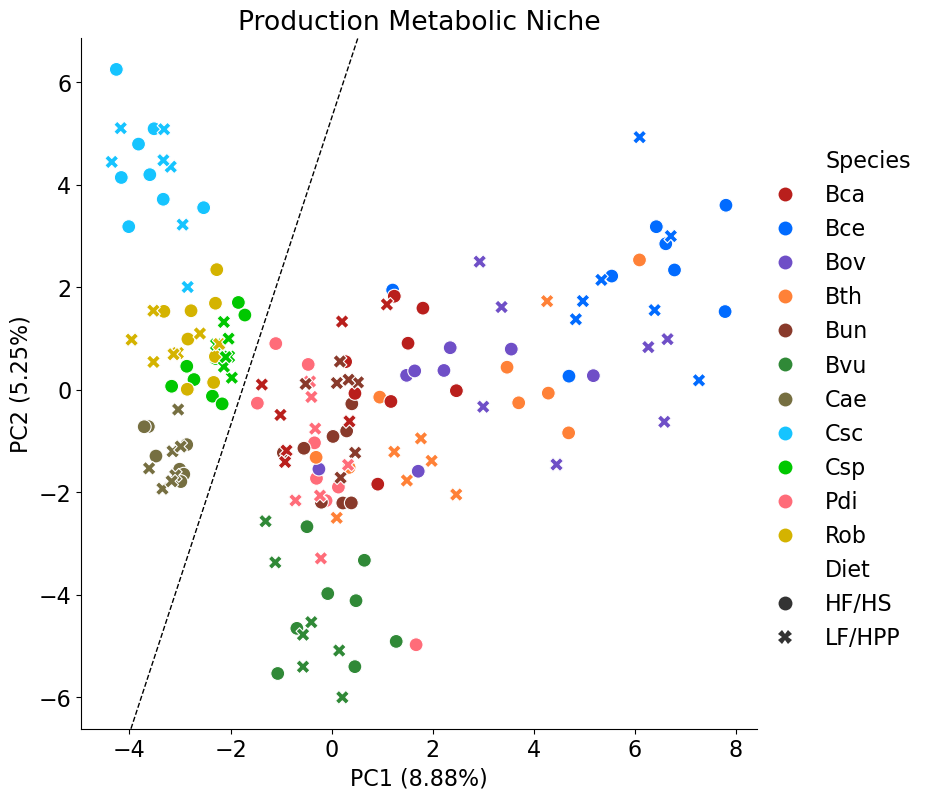

In [22]:
x = exports_mat.values
x = np.log10(x+1e-7)
x = StandardScaler().fit_transform(x)
y = exports_mat.index

pca = PCA(n_components=2)
principalComponents = pca.fit_transform(x)
principalDf = pd.DataFrame(data = principalComponents, columns = ['PC1', 'PC2'])
principalDf.index = y
expl_var = np.round(pca.explained_variance_ratio_* 100, decimals=2)

sns.relplot(
    data=principalDf, 
    x='PC1', 
    y='PC2', 
    hue='Species', 
    style='Diet', 
    palette=cols_ordered, 
    height=8, 
    aspect=1, 
    s=100
    )
plt.title('Production Metabolic Niche')
plt.xlabel(f'PC1 ({expl_var[0]}%)')
plt.ylabel(f'PC2 ({expl_var[1]}%)')
plt.axline((-2.6, -2.5), slope=3, color='black', linestyle='--', linewidth=1)
plt.savefig('results/production_met_niche_total.svg', dpi=300, bbox_inches='tight')
plt.show()